Rows: 62422
Unique patients: 39442
Unique appointments: 49912
Patients with one appointment: 32322
Patients with multiple appointments: 7120
Maximum appointments for one patient: 11


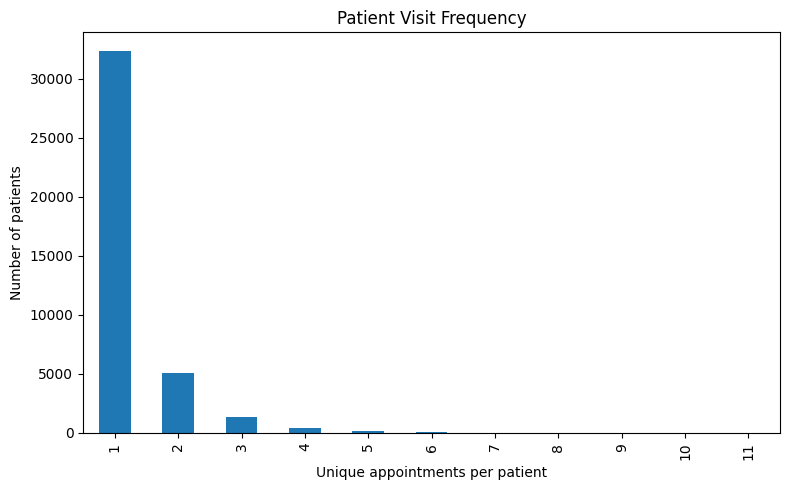

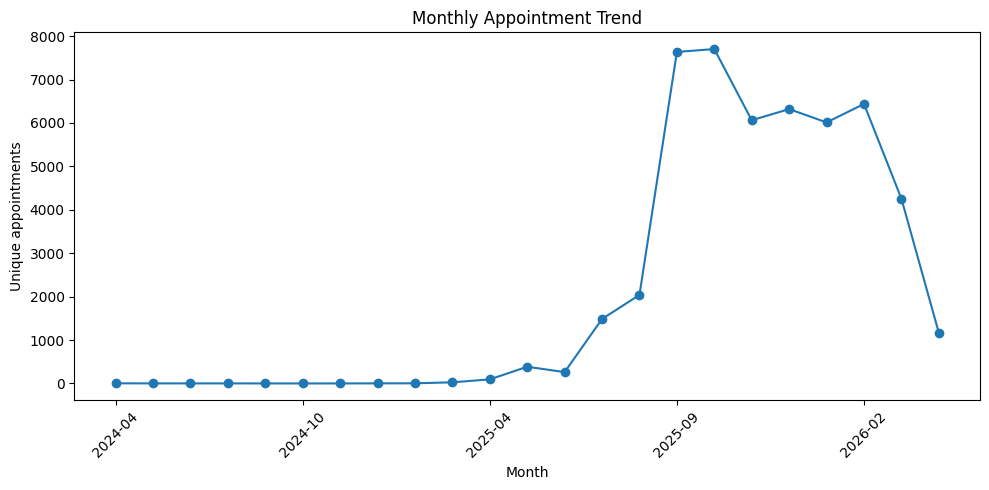

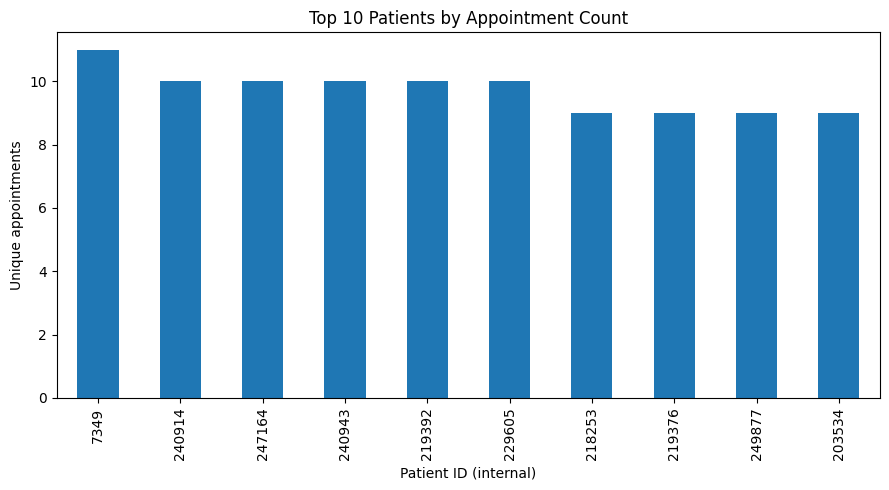

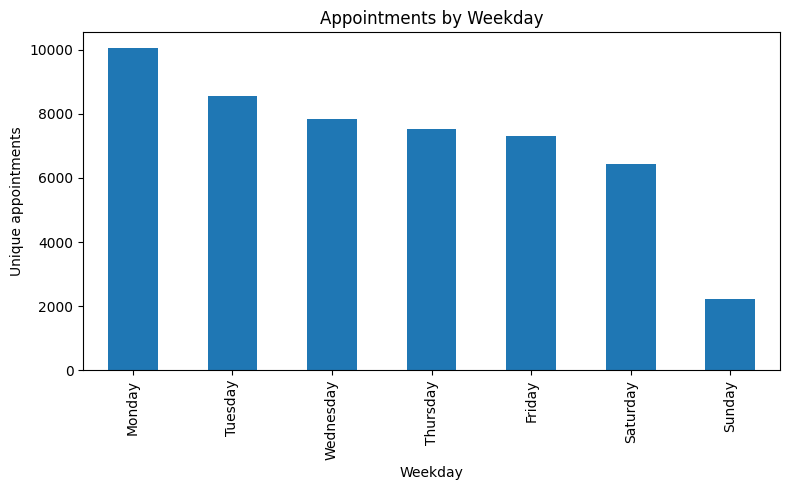

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Upload HospitalOPD_CareFlow_cleaned_v4.xlsx to Colab, then run:
file_path = "/content/HospitalOPD_CareFlow_cleaned_v4.xlsx"
df = pd.read_excel(file_path, sheet_name="Cleaned_Data")
df["appointment_start_datetime"] = pd.to_datetime(df["appointment_start_datetime"], errors="coerce")

# Count distinct appointments, not raw event rows
patient_counts = df.groupby("patient_id")["appointment_id"].nunique().sort_values(ascending=False)
monthly = (df.dropna(subset=["appointment_start_datetime"])
           .assign(month=lambda x: x["appointment_start_datetime"].dt.to_period("M").astype(str))
           .groupby("month")["appointment_id"].nunique().sort_index())
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday = (df.dropna(subset=["appointment_start_datetime"])
           .assign(weekday=lambda x: x["appointment_start_datetime"].dt.day_name())
           .groupby("weekday")["appointment_id"].nunique().reindex(weekday_order))

print("Rows:", len(df))
print("Unique patients:", df["patient_id"].nunique())
print("Unique appointments:", df["appointment_id"].nunique())
print("Patients with one appointment:", (patient_counts == 1).sum())
print("Patients with multiple appointments:", (patient_counts > 1).sum())
print("Maximum appointments for one patient:", patient_counts.max())

plt.figure(figsize=(8,5))
patient_counts.value_counts().sort_index().plot(kind="bar")
plt.title("Patient Visit Frequency"); plt.xlabel("Unique appointments per patient"); plt.ylabel("Number of patients")
plt.tight_layout(); plt.show()

monthly.plot(kind="line", marker="o", figsize=(10,5), title="Monthly Appointment Trend")
plt.xlabel("Month"); plt.ylabel("Unique appointments"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

patient_counts.head(10).plot(kind="bar", figsize=(9,5), title="Top 10 Patients by Appointment Count")
plt.xlabel("Patient ID (internal)"); plt.ylabel("Unique appointments"); plt.tight_layout(); plt.show()

weekday.plot(kind="bar", figsize=(8,5), title="Appointments by Weekday")
plt.xlabel("Weekday"); plt.ylabel("Unique appointments"); plt.tight_layout(); plt.show()

